Week-1 

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [2]:
# Dataset size, feature types, target
print("Shape:", df.shape)
df.info()
print(df.nunique().sort_values())
print("\nTarget distribution:\n", df["Churn"].value_counts(normalize=True).round(3))
print("Duplicates:", df.duplicated().sum())

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [3]:
# Missing values: TotalCharges is text because of blank strings
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isnull().sum()[lambda s: s > 0])
print(df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]])

# All of these customers have tenure = 0 (brand new), so 0 is the logical fill
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")   # identifier, no predictive value

TotalCharges    11
dtype: int64
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


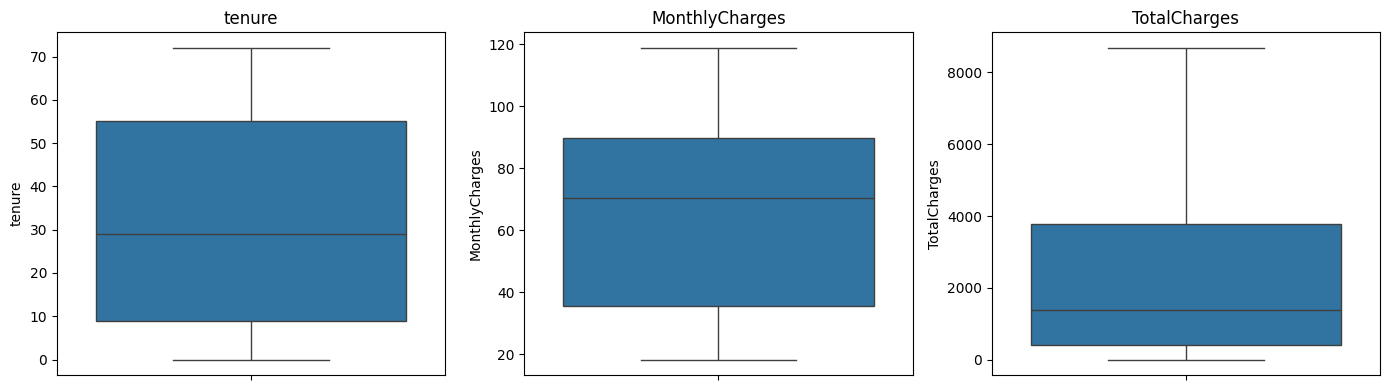

tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


In [4]:
# Outlier detection (boxplots + IQR rule)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c}: {n} outliers")

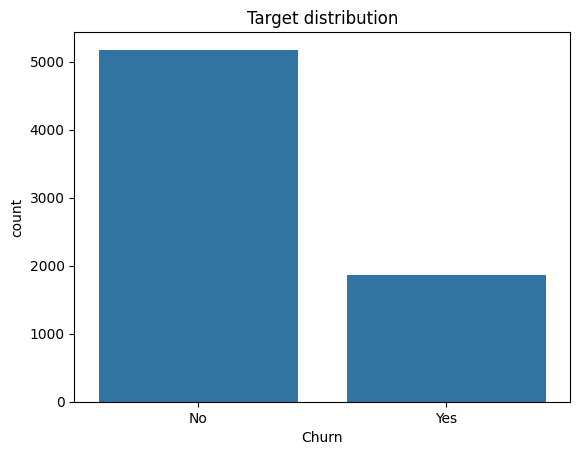

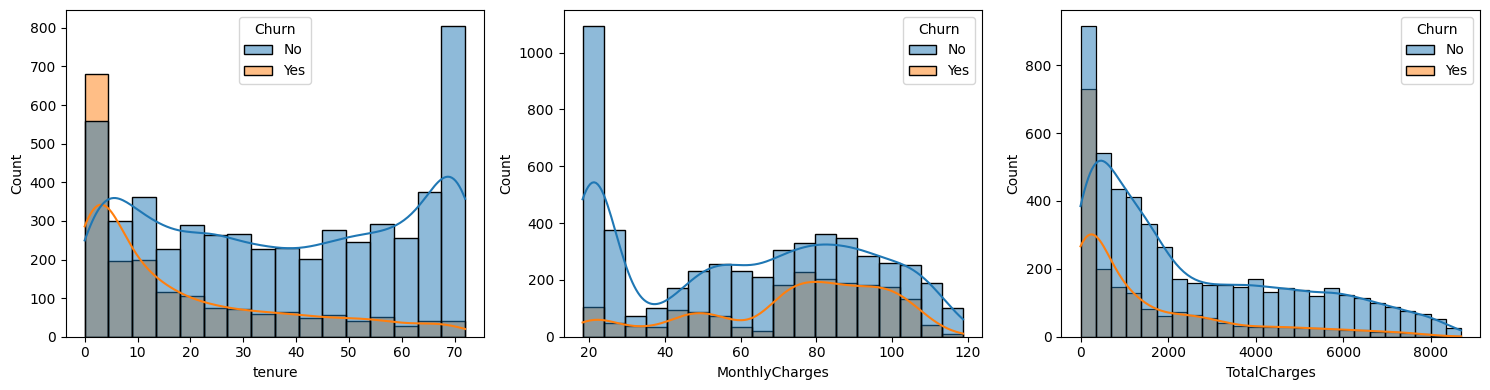

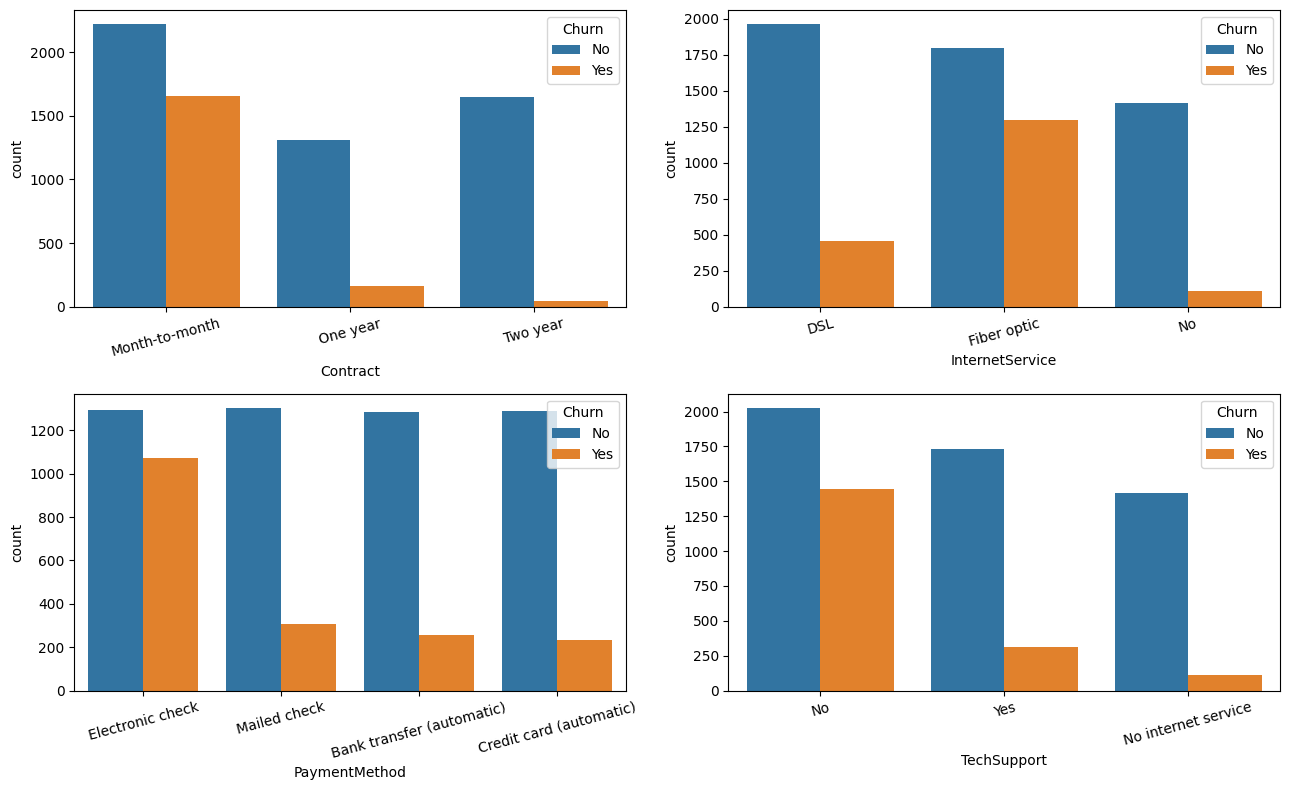

In [5]:
# Distribution analysis
sns.countplot(data=df, x="Churn"); plt.title("Target distribution"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, ax=ax)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), ["Contract", "InternetService", "PaymentMethod", "TechSupport"]):
    sns.countplot(data=df, x=c, hue="Churn", ax=ax); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

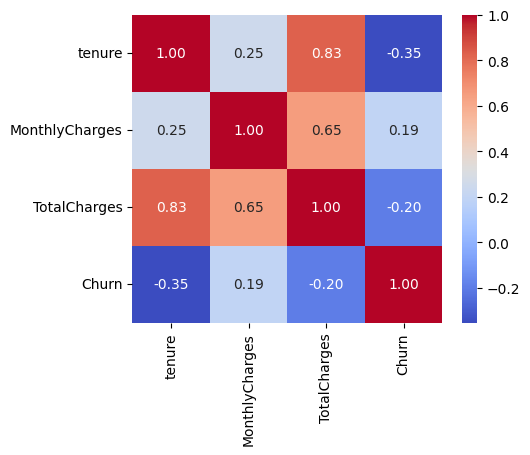

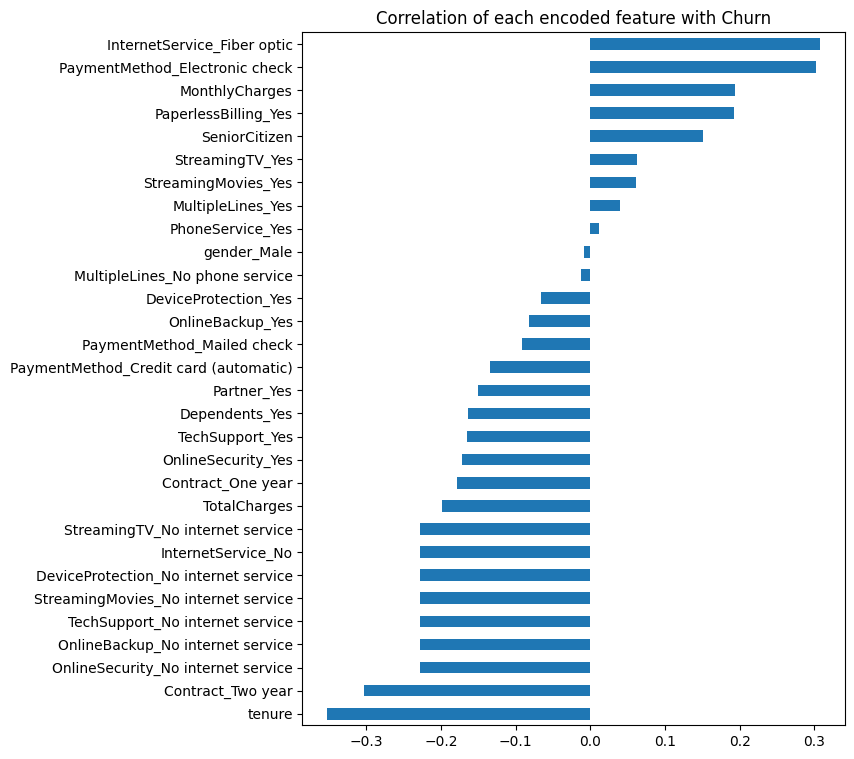

In [6]:
# Correlation analysis (encode a copy only for this purpose)
tmp = df.copy()
tmp["Churn"] = (tmp["Churn"] == "Yes").astype(int)
tmp = pd.get_dummies(tmp, drop_first=True, dtype=int)

plt.figure(figsize=(5, 4))
sns.heatmap(tmp[num_cols + ["Churn"]].corr(), annot=True, cmap="coolwarm", fmt=".2f"); plt.show()

plt.figure(figsize=(7, 9))
tmp.corr()["Churn"].drop("Churn").sort_values().plot(kind="barh")
plt.title("Correlation of each encoded feature with Churn"); plt.show()

In [7]:
X = df.drop(columns="Churn")
y = (df["Churn"] == "Yes").astype(int)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)   # 70/30, class ratio preserved
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(4930, 19) (2113, 19) 0.265 0.265


In [8]:
def evaluate(name, model, Xte, yte):
    pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
    return {"Model": name,
            "Accuracy": accuracy_score(yte, pred), "Precision": precision_score(yte, pred),
            "Recall": recall_score(yte, pred), "F1": f1_score(yte, pred),
            "ROC-AUC": roc_auc_score(yte, proba)}

baselines = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}
fitted, rows = {}, []
for name, m in baselines.items():
    pipe = Pipeline([("prep", make_prep()), ("model", m)]).fit(X_train, y_train)
    fitted[name] = pipe
    rows.append(evaluate(name, pipe, X_test, y_test))

baseline_table = pd.DataFrame(rows).set_index("Model").round(3)
baseline_table

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.809,0.667,0.560,0.609,0.845
Decision Tree,0.730,0.491,0.490,0.491,0.654
KNN,0.763,0.554,0.551,0.552,0.786


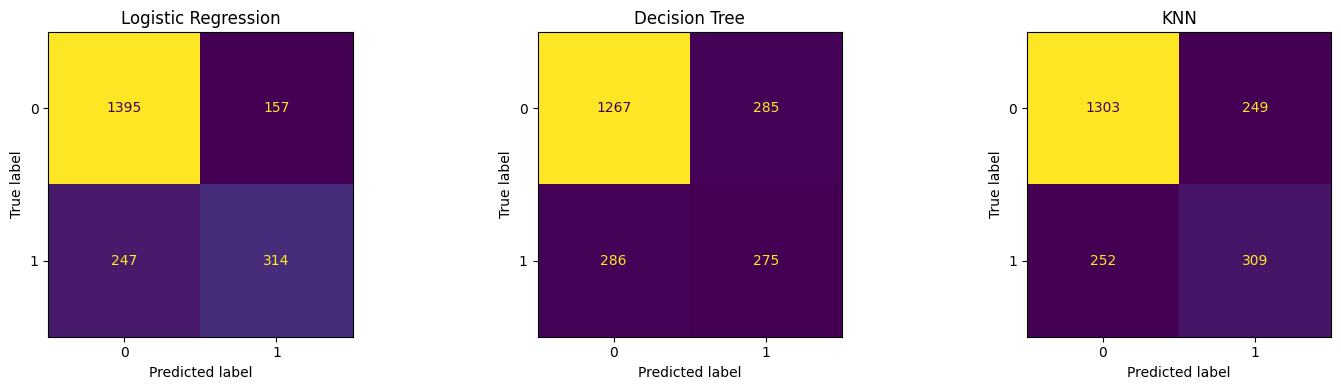

In [9]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

Week-2

In [10]:
# Class imbalance: compare three strategies on Random Forest
variants = {
    "RF, no handling": Pipeline([("prep", make_prep()), ("model", RandomForestClassifier(random_state=42))]),
    "RF, class_weight": Pipeline([("prep", make_prep()), ("model", RandomForestClassifier(class_weight="balanced", random_state=42))]),
    "RF, SMOTE": ImbPipeline([("prep", make_prep()), ("smote", SMOTE(random_state=42)), ("model", RandomForestClassifier(random_state=42))]),
}
imb_rows = []
for name, p in variants.items():
    p.fit(X_train, y_train); imb_rows.append(evaluate(name, p, X_test, y_test))
pd.DataFrame(imb_rows).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
"RF, no handling",0.779,0.606,0.474,0.532,0.814
"RF, class_weight",0.780,0.613,0.471,0.532,0.811
"RF, SMOTE",0.773,0.576,0.545,0.560,0.813


In [11]:
# Hyperparameter tuning: GridSearchCV with 5-fold stratified CV, SMOTE applied inside each training fold only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

searches = {
    "Random Forest": (RandomForestClassifier(random_state=42),
        {"n_estimators": [100, 300], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 5]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=42),
        {"n_estimators": [200, 400], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}),
}

tuned = {}
for name, (est, grid) in searches.items():
    pipe = ImbPipeline([("prep", make_prep()), ("smote", SMOTE(random_state=42)), ("model", est)])
    gs = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()},
                      cv=cv, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name}: best CV F1 = {gs.best_score_:.3f} | {gs.best_params_}")

Random Forest: best CV F1 = 0.629 | {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}
Gradient Boosting: best CV F1 = 0.633 | {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
XGBoost: best CV F1 = 0.629 | {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}


In [12]:
# Cross-validation scores (mean ± std) on training data
cv_rows = []
for name, model in tuned.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    cv_rows.append({"Model": name,
        "CV Accuracy": f"{s['test_accuracy'].mean():.3f} ± {s['test_accuracy'].std():.3f}",
        "CV F1": f"{s['test_f1'].mean():.3f} ± {s['test_f1'].std():.3f}",
        "CV AUC": f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}"})
pd.DataFrame(cv_rows).set_index("Model")

,CV Accuracy,CV F1,CV AUC
Model,,,
Random Forest,0.783 ± 0.015,0.629 ± 0.023,0.841 ± 0.012
Gradient Boosting,0.781 ± 0.018,0.632 ± 0.023,0.843 ± 0.016
XGBoost,0.791 ± 0.017,0.632 ± 0.022,0.843 ± 0.013


In [13]:
# Test-set performance of tuned models + full comparison with baselines
tuned_table = pd.DataFrame([evaluate(n, m, X_test, y_test) for n, m in tuned.items()]).set_index("Model").round(3)
full_table = pd.concat([baseline_table, tuned_table])
full_table.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.809,0.667,0.560,0.609,0.845
XGBoost,0.781,0.573,0.688,0.625,0.842
Gradient Boosting,0.777,0.560,0.736,0.636,0.841
Random Forest,0.776,0.562,0.709,0.627,0.837
KNN,0.763,0.554,0.551,0.552,0.786
Decision Tree,0.730,0.491,0.490,0.491,0.654


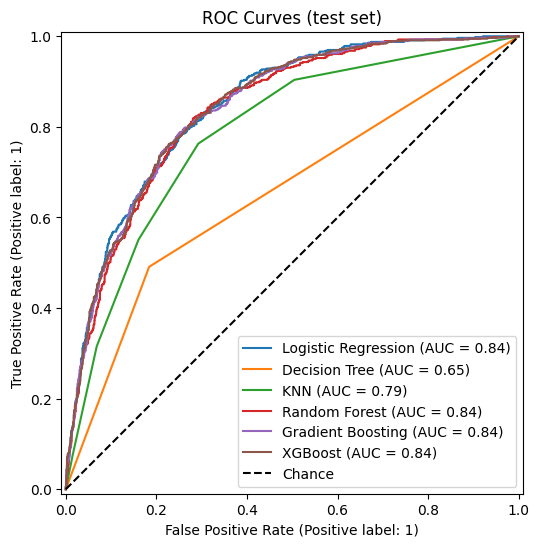

In [14]:
# ROC curves and AUC
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in {**fitted, **tuned}.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Chance"); ax.legend(); ax.set_title("ROC Curves (test set)")
plt.show()

Week - 3

              precision    recall  f1-score   support

        Stay       0.89      0.79      0.84      1552
       Churn       0.56      0.74      0.64       561

    accuracy                           0.78      2113
   macro avg       0.73      0.76      0.74      2113
weighted avg       0.80      0.78      0.79      2113



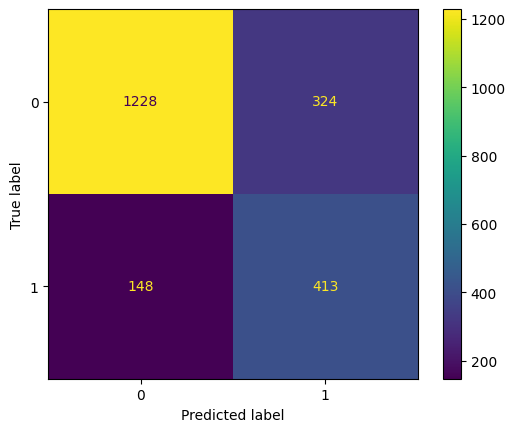

In [15]:
# Pick the best tuned model from the table above, then change this line if needed
final_name = "Gradient Boosting"
final = tuned[final_name]

print(classification_report(y_test, final.predict(X_test), target_names=["Stay", "Churn"]))
ConfusionMatrixDisplay.from_estimator(final, X_test, y_test); plt.show()

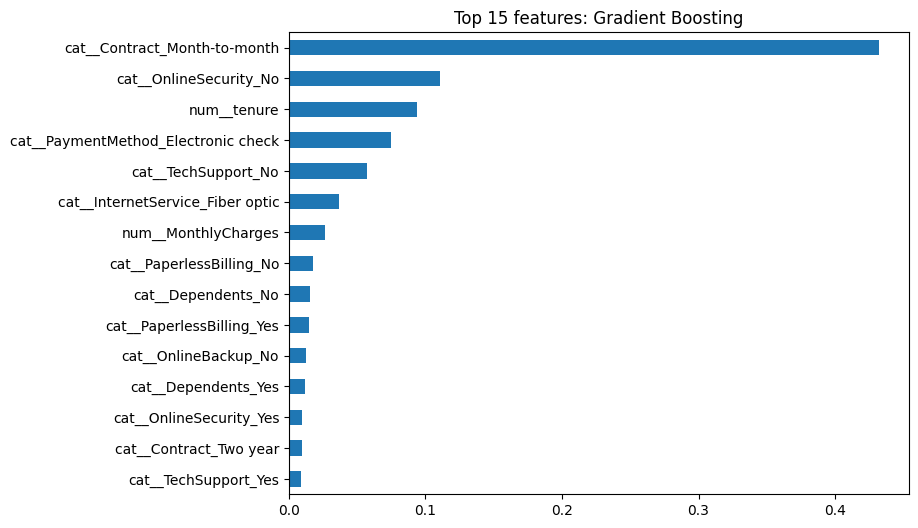

In [16]:
# Feature importance of the final (tree-based) model
names = final.named_steps["prep"].get_feature_names_out()
imp = pd.Series(final.named_steps["model"].feature_importances_, index=names).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 6), title=f"Top 15 features: {final_name}")
plt.show()

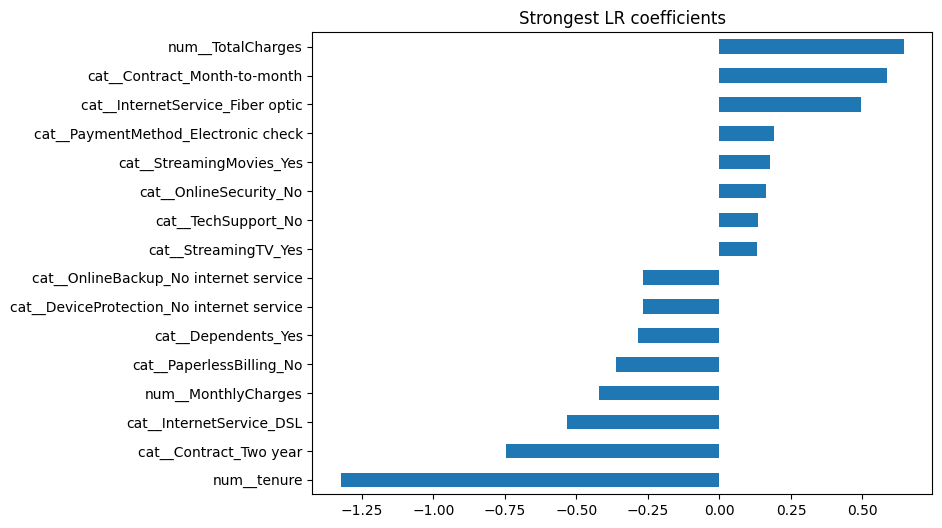

In [17]:
# Direction of effect: Logistic Regression coefficients (positive = more churn)
lr = fitted["Logistic Regression"]
coef = pd.Series(lr.named_steps["model"].coef_[0],
                 index=lr.named_steps["prep"].get_feature_names_out()).sort_values()
pd.concat([coef.head(8), coef.tail(8)]).plot(kind="barh", figsize=(8, 6),
                                             title="Strongest LR coefficients")
plt.show()

In [18]:
# Save for the demo
import joblib
joblib.dump(final, "churn_model.joblib")

['churn_model.joblib']